In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import combinations
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (8, 4.5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.25
print('Entorn preparat.')

Entorn preparat.


## 2.1 Introducció a la base de dades i anàlisi dels atributs i de les correlacions

### 2.1.1 Introducció a la base de dades


In [19]:

# Carregar dataset

df = pd.read_csv("insurance.csv")

print("Dimensions:",df.shape)

print("\nPrimeres files:")
display(df.head())

print("\nTipus d'atributs:")
print(df.dtypes)


Dimensions: (1338, 7)

Primeres files:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Tipus d'atributs:
age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object



En aquest projecte utilitzarem el dataset [Medical Cost Personal Datasets](https://www.kaggle.com/datasets/mirichoi0218/insurance) de Kaggle, que conté inicialment 1.338 registres i 7 columnes relacionades amb les característiques de diferents persones i les seves despeses mèdiques.

L'objectiu és intentar predir les despeses mèdiques (`charges`) d'una persona a partir de sis atributs:

- `age`: edat de la persona.
- `sex`: sexe de la persona.
- `bmi`: índex de massa corporal.
- `children`: nombre de fills o dependents.
- `smoker`: indica si la persona és fumadora.
- `region`: regió de residència.

La variable objectiu (*target*) és `charges`, que representa les despeses mèdiques facturades de cada persona. Com que és una variable numèrica contínua, ens trobem davant d'un problema de regressió, en el qual volem predir aquestes despeses a partir dels altres sis atributs del dataset.

### 2.1.2 Anàlisi dels atributs i de les correlacions.

#### Càrrega, neteja i partició de les dades

In [ ]:

# Carregar dataset
print("Primeres files:")
display(df.head())

print("\nFiles inicials:",len(df))
print("Columnes:",len(df.columns))

print("\nDuplicats trobats:",df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("Files després d'eliminar duplicats:",len(df))


# Definir variables

variables_numericas = ["age","bmi","children"]
variables_categoricas = ["sex","smoker","region"]
atributs = ["age","sex","bmi","children","smoker","region"]
target = "charges"


# Separar atributs i target

X = df.drop(columns=[target])
y = df[target]


# Separar train, validation i test

X_train, X_resto, y_train, y_resto = train_test_split(X,y,test_size=0.40,random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_resto,y_resto,test_size=0.50,random_state=RANDOM_STATE)

print("\nDimensions dels conjunts:")
print("Train:",X_train.shape)
print("Validation:",X_val.shape)
print("Test:",X_test.shape)


# Crear dataframe de train per fer l'EDA

df_train = X_train.copy()
df_train[target] = y_train

print("\nTipus d'atributs:")
print(df_train.dtypes)

print("\nValors nuls en train:")
print(df_train.isnull().sum())


Primeres files:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Files inicials: 1338
Columnes: 7

Duplicats trobats: 1
Files després d'eliminar duplicats: 1337

Dimensions dels conjunts:
Train: (802, 6)
Validation: (267, 6)
Test: (268, 6)

Tipus d'atributs:
age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

Valors nuls en train:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


Inicialment, el dataset conté 1.338 registres i 7 atributs, dels quals 4 són numèrics i 3 categòrics. Hem eliminat un registre duplicat, quedant 1.337 registres. No s'han trobat valors nuls a train, per tant no cal aplicar cap tècnica d'imputació.

Hem dividit les dades en train (60%, 802 registres), validation (20%, 267 registres) i test (20%, 268 registres). Aquesta separació es fa abans de l'EDA per evitar *data leakage*, reservant el test per a l'avaluació final.

#### Valors perduts

Valors nuls per atribut:


,Valors nuls
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


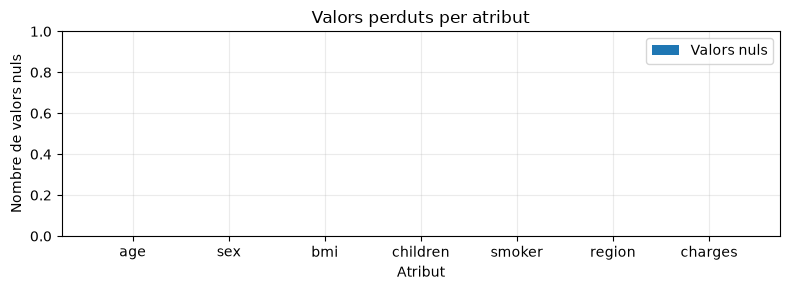

In [18]:

# Valors perduts

valors_nuls = df_train.isnull().sum()

print("Valors nuls per atribut:")
display(valors_nuls.to_frame("Valors nuls"))

plt.figure(figsize=(8,3))
plt.bar(valors_nuls.index,valors_nuls.values,label="Valors nuls")
plt.title("Valors perduts per atribut")
plt.xlabel("Atribut")
plt.ylabel("Nombre de valors nuls")
plt.ylim(0,1)
plt.legend()
plt.tight_layout()
plt.show()


Com podem veure, no tenim cap valor nul en els atributs. Això ens simplifica el preprocessament, ja que no necessitem eliminar més registres ni aplicar tècniques d'imputació. Per tant, podem centrar-nos directament a preparar les variables per als models.

#### Distribució de la variable objectiu

Estadístiques de charges:


count      802.00
mean     13050.20
std      11577.25
min       1121.87
25%       4773.43
50%       9289.08
75%      17071.65
max      58571.07
Name: charges, dtype: float64

Asimetria: 1.48


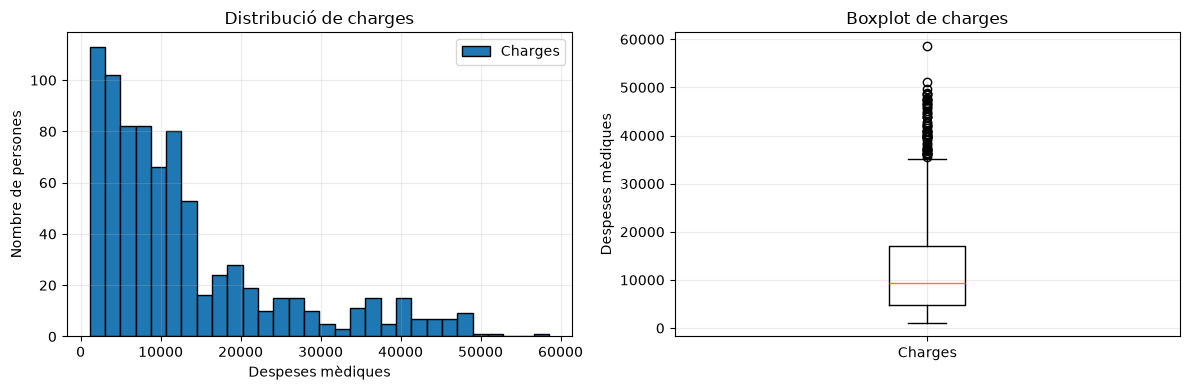

In [11]:

# Distribució del target

print("Estadístiques de charges:")
display(df_train[target].describe().round(2))

print("Asimetria:",round(df_train[target].skew(),2))


# Gràfics de charges

fig, axes = plt.subplots(1,2,figsize=(12,4))

axes[0].hist(df_train[target],bins=30,edgecolor="black",label="Charges")
axes[0].set_title("Distribució de charges")
axes[0].set_xlabel("Despeses mèdiques")
axes[0].set_ylabel("Nombre de persones")
axes[0].legend()

axes[1].boxplot(df_train[target])
axes[1].set_title("Boxplot de charges")
axes[1].set_ylabel("Despeses mèdiques")
axes[1].set_xticks([1])
axes[1].set_xticklabels(["Charges"])

plt.tight_layout()
plt.show()


Mirant l'histograma veiem que la majoria de persones tenen despeses mèdiques relativament baixes, però algunes presenten despeses molt més elevades. Això explica que la mitjana (13.050,20) sigui bastant més alta que la mediana (9.289,08).

Aquests valors tan elevats ens fan pensar que potser hi ha algun patró o característica en comú entre aquestes persones que expliqui aquesta diferència. Per això, en els següents apartats intentarem descobrir quins atributs estan més relacionats amb aquestes despeses.

#### Anàlisi de les variables categòriques

Mitjana general de charges: 13050.2

Resultats segons sex


,sex,Persones,Charges mitjà,Diferència (%)
0,female,383,12362.78,-5.27
1,male,419,13678.56,4.81



Resultats segons smoker


,smoker,Persones,Charges mitjà,Diferència (%)
0,no,632,8410.01,-35.56
1,yes,170,30300.80,132.19



Resultats segons region


,region,Persones,Charges mitjà,Diferència (%)
0,northeast,186,13810.46,5.83
1,northwest,201,12151.94,-6.88
2,southeast,219,13782.16,5.61
3,southwest,196,12432.05,-4.74


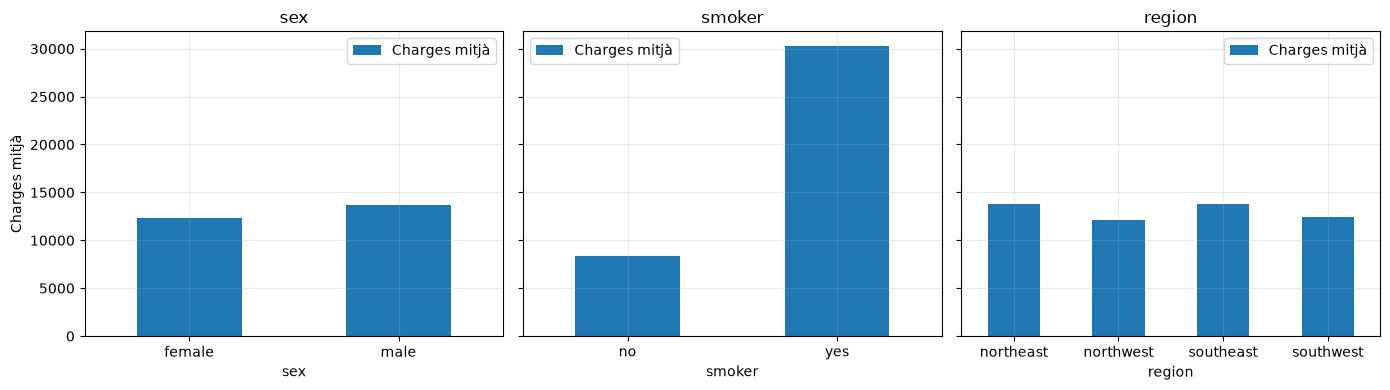

In [12]:

# Analitzar variables categòriques

media_general = df_train[target].mean()

print("Mitjana general de charges:",round(media_general,2))

for variable in variables_categoricas:

    taula = df_train.groupby(variable)[target].agg(["count","mean"]).reset_index()

    taula["Diferència (%)"] = ((taula["mean"] - media_general) / media_general) * 100

    taula.columns = [variable,"Persones","Charges mitjà","Diferència (%)"]

    taula["Charges mitjà"] = taula["Charges mitjà"].round(2)
    taula["Diferència (%)"] = taula["Diferència (%)"].round(2)

    print("\nResultats segons",variable)
    display(taula)


# Gràfics de variables categòriques

fig, axes = plt.subplots(1,3,figsize=(14,4),sharey=True)

for i,variable in enumerate(variables_categoricas):

    mitjanes = df_train.groupby(variable)[target].mean()

    mitjanes.plot(kind="bar",ax=axes[i],title=variable,label="Charges mitjà",rot=0)

    axes[i].set_xlabel(variable)
    axes[i].set_ylabel("Charges mitjà")
    axes[i].legend()

plt.tight_layout()
plt.show()


Mirant les taules i els gràfics veiem que `smoker` destaca molt respecte als altres atributs. Les persones fumadores tenen unes despeses mitjanes de 30.300,80, mentre que les no fumadores tenen una mitjana de 8.410,01. Per tant, els fumadors tenen unes despeses aproximadament 3,6 vegades més altes.

Això ens dona una primera pista sobre els valors tan elevats que havíem vist abans: potser el fet de fumar està relacionat amb aquestes despeses més altes. En canvi, les diferències segons `sex` i `region` són molt més petites.

En els següents apartats comprovarem si `smoker` és realment l'atribut més relacionat amb `charges` o si hi ha altres variables que també tenen una relació important.

#### Correlacions i relació individual dels atributs

Correlacions numèriques:


,Atribut,Correlació amb charges
0,age,0.304
1,bmi,0.147
2,children,0.092



Variació explicada per cada atribut:


,Atribut,% variació explicada
4,smoker,59.80
0,age,9.24
2,bmi,2.17
3,children,0.85
5,region,0.43
1,sex,0.32


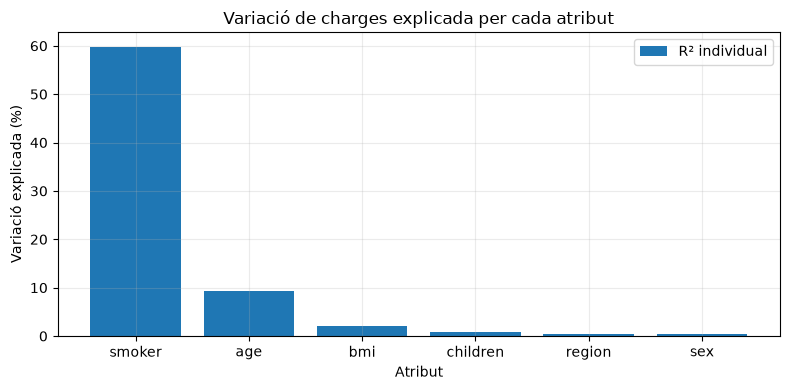

In [14]:

# Correlacions numèriques

resultats_correlacio = []

for variable in variables_numericas:
    correlacio = df_train[variable].corr(df_train[target])
    resultats_correlacio.append([variable,correlacio])

taula_correlacio = pd.DataFrame(resultats_correlacio,columns=["Atribut","Correlació amb charges"])

print("Correlacions numèriques:")
display(taula_correlacio.round(3))


# Percentatge de variació explicada

def percentatge_explicat(variables):

    X_analisi = df_train[variables].copy()
    X_analisi = pd.get_dummies(X_analisi,drop_first=True,dtype=int)

    model = LinearRegression()
    model.fit(X_analisi,df_train[target])

    return model.score(X_analisi,df_train[target]) * 100


# Relació individual de cada atribut

resultats_individuals = []

for atribut in atributs:
    percentatge = percentatge_explicat([atribut])
    resultats_individuals.append([atribut,percentatge])

taula_individual = pd.DataFrame(resultats_individuals,columns=["Atribut","% variació explicada"])
taula_individual = taula_individual.sort_values("% variació explicada",ascending=False)

print("\nVariació explicada per cada atribut:")
display(taula_individual.round(2))


# Gràfic de variació explicada

plt.figure(figsize=(8,4))
plt.bar(taula_individual["Atribut"],taula_individual["% variació explicada"],label="R² individual")
plt.title("Variació de charges explicada per cada atribut")
plt.xlabel("Atribut")
plt.ylabel("Variació explicada (%)")
plt.legend()
plt.tight_layout()
plt.show()


Mirant les correlacions numèriques veiem que `age` és l'atribut que té més relació lineal amb `charges` (0,304), tot i que tampoc és gaire elevada.

En canvi, quan comparem els sis atributs amb el R², veiem que `smoker` destaca molt, ja que explica aproximadament el 59,80% de la variació de `charges`, mentre que `age` només explica un 9,24%. Això reforça la nostra sospita anterior sobre els fumadors i ens fa pensar que potser combinant `smoker` amb altres atributs podrem explicar encara més aquestes diferències.

#### Combinacions d'atributs

In [15]:

# Relació entre parelles d'atributs

resultats_parelles = []

for atribut1, atribut2 in combinations(atributs,2):

    percentatge1 = percentatge_explicat([atribut1])
    percentatge2 = percentatge_explicat([atribut2])
    percentatge_junts = percentatge_explicat([atribut1,atribut2])

    millor_individual = max(percentatge1,percentatge2)
    millora = percentatge_junts - millor_individual

    resultats_parelles.append([atribut1,percentatge1,atribut2,percentatge2,percentatge_junts,millora])

taula_parelles = pd.DataFrame(resultats_parelles,columns=["Atribut 1","% Atribut 1","Atribut 2","% Atribut 2","% Junts","Millora"])
taula_parelles = taula_parelles.sort_values("% Junts",ascending=False)

print("Relació entre parelles d'atributs:")
display(taula_parelles.round(2))


# Relació entre combinacions de 3 atributs

resultats_triples = []

for combinacio in combinations(atributs,3):

    percentatge = percentatge_explicat(list(combinacio))

    if percentatge >= 70:
        resultats_triples.append([" + ".join(combinacio),percentatge])

taula_triples = pd.DataFrame(resultats_triples,columns=["Atributs","% variació explicada"])
taula_triples = taula_triples.sort_values("% variació explicada",ascending=False)

print("\nCombinacions de 3 atributs amb R² igual o superior al 70%:")
display(taula_triples.round(2))


# Relació utilitzant tots els atributs

percentatge_total = percentatge_explicat(atributs)

print("\nVariació de charges explicada utilitzant tots els atributs:",round(percentatge_total,2),"%")


Relació entre parelles d'atributs:


,Atribut 1,% Atribut 1,Atribut 2,% Atribut 2,% Junts,Millora
3,age,9.24,smoker,59.80,70.70,10.91
10,bmi,2.17,smoker,59.80,63.67,3.88
12,children,0.85,smoker,59.80,60.29,0.49
14,smoker,59.80,region,0.43,59.87,0.07
7,sex,0.32,smoker,59.80,59.80,0.01
1,age,9.24,bmi,2.17,10.49,1.25
2,age,9.24,children,0.85,9.77,0.53
4,age,9.24,region,0.43,9.66,0.42
0,age,9.24,sex,0.32,9.56,0.32
9,bmi,2.17,children,0.85,3.02,0.84



Combinacions de 3 atributs amb R² igual o superior al 70%:


,Atributs,% variació explicada
1,age + bmi + smoker,73.23
2,age + children + smoker,70.94
3,age + smoker + region,70.76
0,age + sex + smoker,70.71



Variació de charges explicada utilitzant tots els atributs: 73.59 %


Mirant les parelles d'atributs veiem que combinar `age` amb `smoker` millora bastant el resultat, passant del 59,80% al 70,70% de variació explicada. En canvi, afegir `sex` o `region` a `smoker` gairebé no aporta informació nova.

Quan provem combinacions de tres atributs, veiem que `age + bmi + smoker` arriba al 73,23%, mentre que utilitzant tots sis atributs només augmenta fins al 73,59%.

Això ens fa pensar que aquests tres atributs contenen gran part de la informació que aprofita la regressió lineal per explicar les despeses mèdiques. Tot i així, no descartarem els altres atributs encara, perquè potser altres models poden aprofitar relacions que la regressió lineal no detecta.

#### Relació entre BMI, smoker i charges

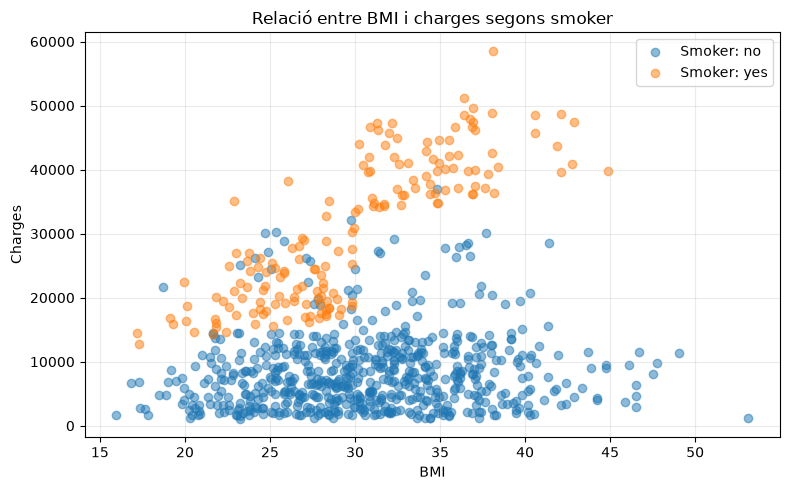

Correlació entre BMI i charges segons smoker:


,Smoker,Persones,Correlació BMI-Charges
0,no,632,0.091
1,yes,170,0.822


In [17]:

# Relació entre BMI, smoker i charges

resultats_bmi = []

plt.figure(figsize=(8,5))

for fuma in ["no","yes"]:

    dades = df_train[df_train["smoker"] == fuma]

    correlacio = dades["bmi"].corr(dades[target])
    resultats_bmi.append([fuma,len(dades),correlacio])

    plt.scatter(dades["bmi"],dades[target],alpha=0.5,label="Smoker: "+fuma)

plt.title("Relació entre BMI i charges segons smoker")
plt.xlabel("BMI")
plt.ylabel("Charges")
plt.legend()
plt.tight_layout()
plt.show()

taula_bmi = pd.DataFrame(resultats_bmi,columns=["Smoker","Persones","Correlació BMI-Charges"])

print("Correlació entre BMI i charges segons smoker:")
display(taula_bmi.round(3))


En separar fumadors i no fumadors observem que, entre els fumadors, les despeses mèdiques augmenten de manera aproximadament lineal a mesura que augmenta el BMI (correlació de 0,822). En canvi, entre els no fumadors gairebé no veiem aquesta relació (0,091).

Això és interessant perquè abans havíem vist que el BMI per si sol tenia poca relació amb `charges`, però ara descobrim que aquesta relació canvia molt depenent de si la persona fuma o no.

## 2.2 Mètode, **2.5 punts**

Cal escollir una sèrie de models i, mitjançant validació creuada, seleccionar el millor amb els seus hiperparàmetres òptims. Expliqueu breument què fa cada model, sobretot els que no s’han vist a classe, i per què l’heu triat.

**Mínim per al 7.5:** calcular una baseline, triar i justificar la mètrica, comparar com a mínim quatre models amb validació creuada i fer una cerca d’hiperparàmetres per a cadascun, tot ajustat només amb train i dins d’un Pipeline.

El conjunt de test es reserva per al final: només s’utilitza una vegada, amb el model ja triat, i cap decisió (model, hiperparàmetres, mètrica, llindar) es pren mirant el test.

## 2.3 Descripció dels resultats, **3 punts**

Un cop seleccionat el model final, cal elaborar un report amb els resultats.

**Mínim per al 7.5:** indicar quin és el model final i amb quin criteri l’heu triat abans de mirar el test, avaluar-lo al test una sola vegada, mostrar les gràfiques que corresponguin a la vostra tasca i explicar un cas d’ús i possibles millores.

## 2.4 Repositori de GitHub, **1 punt**

El repositori és el lliurament: qualsevol persona ha de poder entendre què heu fet i reproduir-ho. A `github.pdf` trobareu com crear-lo i com treballar amb Git.

**Mínim per al 7.5:** un repositori que es pugui executar d’extrem a extrem, amb un README.

**Què ha de tenir:**

-  Un `README.md` amb la pregunta, la base de dades (amb l’enllaç a Kaggle), els resultats principals i com executar el projecte.
-  Un o més notebooks que s’executin d’extrem a extrem, amb text que expliqui cada decisió i el resultat que se n’ha derivat.
-  Un fitxer amb les llibreries necessàries i una llavor (*seed*) fixada allà on hi hagi aleatorietat.
-  Les dades només si són petites; si no, l’enllaç per descarregar-les.
-  Un historial de *commits* en què es vegi la feina de cada membre del grup.
-  L’usuari `silvanasp` afegit com a col·laborador del repositori (a GitHub, *Settings*, *Collaborators*), perquè hi pugui accedir encara que sigui privat.

Una organització possible és:

```
projecte-ml/
|-- data/
|-- notebooks/
|   |-- 01_exploration.ipynb
|   `-- 02_models.ipynb
|-- src/
`-- README.md
```

Podeu trobar exemples de notebooks aplicats a casos concrets a [datauab.github.io](https://datauab.github.io/).

# Presentació i declaració d’ús d’IA

**Presentació (opcional), 1 punt.** Es farà a la sessió 6, el 15 de desembre, i serà de 4 minuts, més preguntes. Si no penseu presentar, no cal que us apunteu a un grup d’avaluació a Caronte, i el cas es puntuarà igualment, amb un 0 a l'apartat de presentació i, per tant, una nota màxima de 9.0. Si voleu presentar, apunteu-vos al grup d’avaluació que us vagi bé. Tots els membres del grup s’han de connectar a la sessió amb la càmera encesa durant tota la presentació, no només quan parlen, i han de parlar; qui no tingui la càmera encesa o no intervingui no podrà ser avaluat. Porteu a les diapositives la pregunta, el model final amb els hiperparàmetres, el criteri de tria, el resultat al test i una figura que sostingui la decisió principal.

**Declaració d’ús d’IA.** Si heu utilitzat eines d’IA, declareu-ho al final del repositori (quina i per a què).

# Recursos

* `kaggle.xlsx`: llista de bases de dades revisades.
* `github.pdf`: Git i GitHub.
* `data_leakage.pdf`: què és el *data leakage* i en quins passos del preprocessament apareix.
* [datauab.github.io](https://datauab.github.io/): exemples de notebooks.